### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Statistical and Probabilistic Techniques**

Models with an **explicit probabilistic formulation**: they estimate parameters, quantify **uncertainty** and allow **statistical inference**.

| Technique | Target | Estimation | Typical output |
|---|---|---|---|
| **Linear regression** | continuous | least squares (OLS) | value + prediction interval |
| **Logistic regression** | binary | maximum likelihood (IRLS) | probability + odds ratios |
| **Bayesian network** | many variables (discrete) | counting (MLE/Laplace) + structure search | any conditional probability |

Each one is implemented **from scratch** (NumPy) and checked against `scikit-learn`.

### **2. Linear Regression**

$y = X\beta + \epsilon$, with $\epsilon \sim N(0, \sigma^2)$. Ordinary least squares minimises $\lVert y - X\beta \rVert^2$:

$$\hat{\beta} = (X^T X)^{-1} X^T y \qquad \text{Var}(\hat{\beta}) = \hat{\sigma}^2 (X^T X)^{-1}$$

**Assumptions:** linearity · independent errors · constant variance (homoscedasticity) · normal errors · no strong multicollinearity.

Data: **Diabetes** (442 patients, 10 attributes, target = disease progression), 80/20 split.

In [4]:
#Load the Diabetes Dataset and Split ( 80% Train / 20% Test )
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

dia = load_diabetes(as_frame=True)
Xd, yd = dia.data, dia.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=RANDOM_STATE)
print("train:", Xd_tr.shape, "| test:", Xd_te.shape)
Xd_tr.head(3)

train: (353, 10) | test: (89, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
17,0.071,0.051,0.012,0.056,0.034,0.049,-0.040,0.034,2.736e-02,-0.001
66,-0.009,0.051,-0.018,-0.033,-0.021,0.012,-0.073,0.071,2.725e-04,0.020
137,0.005,-0.045,0.050,0.098,-0.015,-0.016,-0.007,-0.003,1.704e-02,-0.014


In [5]:
#OLS Implementation from Scratch ( Normal Equations, Standard Errors, t-Tests, F-Test, AIC/BIC )
from scipy import stats

class OLS:
    def fit(self, X, y):
        A = np.c_[np.ones(len(X)), np.asarray(X, float)]
        y = np.asarray(y, float)
        self.names_ = ["intercept"] + list(X.columns)
        self.XtX_inv_ = np.linalg.inv(A.T @ A)
        self.beta_ = self.XtX_inv_ @ A.T @ y
        self.n_, self.p_ = A.shape
        self.resid_ = y - A @ self.beta_
        self.sse_, self.sst_ = self.resid_ @ self.resid_, ((y - y.mean()) ** 2).sum()
        self.s2_ = self.sse_ / (self.n_ - self.p_)
        self.se_ = np.sqrt(np.diag(self.s2_ * self.XtX_inv_))
        self.leverage_ = np.einsum("ij,jk,ik->i", A, self.XtX_inv_, A)
        self.A_ = A
        return self

    def predict(self, X):
        return np.c_[np.ones(len(X)), np.asarray(X, float)] @ self.beta_

    def summary(self, level=0.95):
        t = self.beta_ / self.se_
        df = self.n_ - self.p_
        crit = stats.t.ppf(1 - (1 - level) / 2, df)
        return pd.DataFrame({"coef": self.beta_, "std err": self.se_, "t": t, "p-value": 2 * stats.t.sf(np.abs(t), df),
                             "CI low": self.beta_ - crit * self.se_, "CI high": self.beta_ + crit * self.se_}, index=self.names_)

    def fit_stats(self):
        r2 = 1 - self.sse_ / self.sst_
        k = self.p_ - 1
        F = (r2 / k) / ((1 - r2) / (self.n_ - self.p_))
        ll = -self.n_ / 2 * (np.log(2 * np.pi) + np.log(self.sse_ / self.n_) + 1)
        return {"R²": r2, "adjusted R²": 1 - (1 - r2) * (self.n_ - 1) / (self.n_ - self.p_), "F-statistic": F,
                "F p-value": stats.f.sf(F, k, self.n_ - self.p_), "log-likelihood": ll,
                "AIC": 2 * (self.p_ + 1) - 2 * ll, "BIC": (self.p_ + 1) * np.log(self.n_) - 2 * ll}

    def prediction_interval(self, X, level=0.95):
        A = np.c_[np.ones(len(X)), np.asarray(X, float)]
        pred, h = A @ self.beta_, np.einsum("ij,jk,ik->i", A, self.XtX_inv_, A)
        half = stats.t.ppf(1 - (1 - level) / 2, self.n_ - self.p_) * np.sqrt(self.s2_ * (1 + h))
        return pred, pred - half, pred + half

ols = OLS().fit(Xd_tr, yd_tr)
from sklearn.linear_model import LinearRegression
print("coefficients identical to scikit-learn:", np.allclose(ols.beta_[1:], LinearRegression().fit(Xd_tr, yd_tr).coef_))
ols.summary().round(3)

coefficients identical to scikit-learn: True


,coef,std err,t,p-value,CI low,CI high
intercept,151.346,2.902,52.155,0.000,145.638,157.053
age,37.904,69.056,0.549,0.583,-97.923,173.731
sex,-241.964,68.570,-3.529,0.000,-376.836,-107.093
bmi,542.429,76.956,7.049,0.000,391.062,693.795
bp,347.704,71.357,4.873,0.000,207.350,488.057
s1,-931.489,451.138,-2.065,0.040,-1818.844,-44.134
s2,518.062,364.114,1.423,0.156,-198.122,1234.247
s3,163.420,233.014,0.701,0.484,-294.901,621.741
s4,275.318,185.400,1.485,0.138,-89.349,639.985
s5,736.199,192.437,3.826,0.000,357.689,1114.709


In [6]:
#Global Fit Statistics ( R², Adjusted R², F-Test, Log-Likelihood, AIC and BIC )
pd.Series(ols.fit_stats()).to_frame("training fit").round(4).T

,R²,adjusted R²,F-statistic,F p-value,log-likelihood,AIC,BIC
training fit,0.528,0.514,38.245,0.0,-1906.101,3836.202,3882.6


#### **Predictive Metrics on the Test Set**

**MAE**, **RMSE**, **R²** and the **interval coverage**: the share of true values that fall inside the 95 % **prediction interval** (it should be ≈ 95 %).

,MAE,MedAE,RMSE,R²,95% PI coverage,mean PI width
OLS (test set),42.794,37.988,53.853,0.453,0.966,217.356


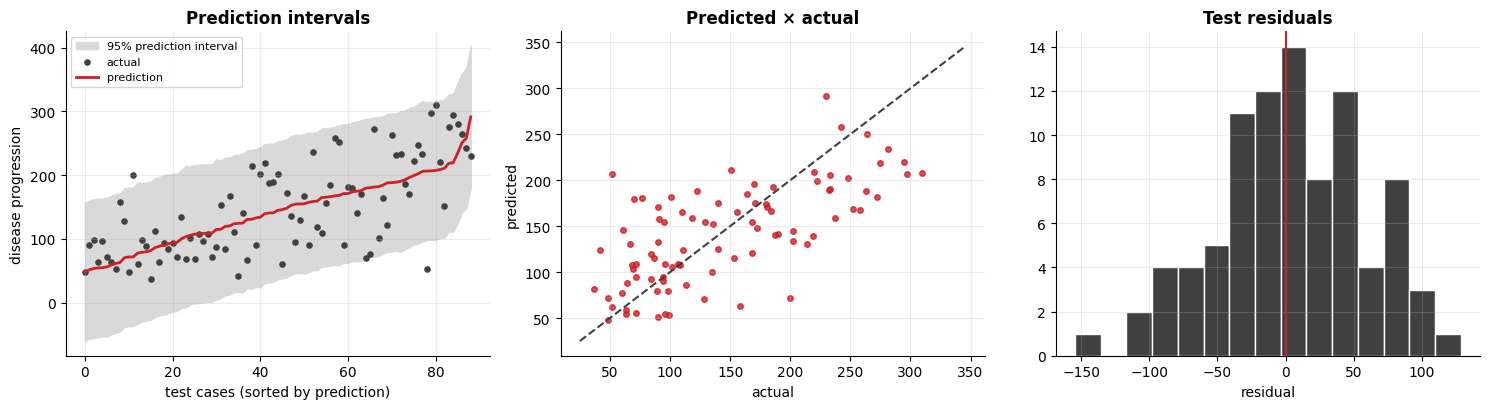

In [7]:
#Test-Set Metrics, Predicted × Actual and Residual Plots
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

pred_te, lo, hi = ols.prediction_interval(Xd_te)
metrics_lin = {"MAE": mean_absolute_error(yd_te, pred_te), "MedAE": median_absolute_error(yd_te, pred_te),
               "RMSE": np.sqrt(mean_squared_error(yd_te, pred_te)), "R²": r2_score(yd_te, pred_te),
               "95% PI coverage": float(((yd_te >= lo) & (yd_te <= hi)).mean()), "mean PI width": float((hi - lo).mean())}
display(pd.Series(metrics_lin, name="OLS (test set)").to_frame().T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = np.argsort(pred_te)
axes[0].fill_between(range(len(order)), lo[order], hi[order], color=LIGHT, label="95% prediction interval")
axes[0].scatter(range(len(order)), yd_te.to_numpy()[order], s=14, color=DARK, label="actual"); axes[0].plot(pred_te[order], color=RED, lw=2, label="prediction")
axes[0].set_xlabel("test cases (sorted by prediction)"); axes[0].set_ylabel("disease progression"); axes[0].set_title("Prediction intervals"); axes[0].legend(fontsize=8)
axes[1].scatter(yd_te, pred_te, s=16, color=RED, alpha=0.8); axes[1].plot([yd.min(), yd.max()], [yd.min(), yd.max()], color=DARK, ls="--")
axes[1].set_xlabel("actual"); axes[1].set_ylabel("predicted"); axes[1].set_title("Predicted × actual")
axes[2].hist(yd_te - pred_te, bins=15, color=DARK, edgecolor="white"); axes[2].axvline(0, color=RED); axes[2].set_xlabel("residual"); axes[2].set_title("Test residuals")
plt.tight_layout(); plt.show()

#### **Checking the Assumptions (Diagnostics)**

* **Residuals × fitted:** no pattern (linearity) and constant spread (homoscedasticity)
* **Q-Q plot:** points on the line (normality)
* **Leverage / Cook's distance:** influential observations

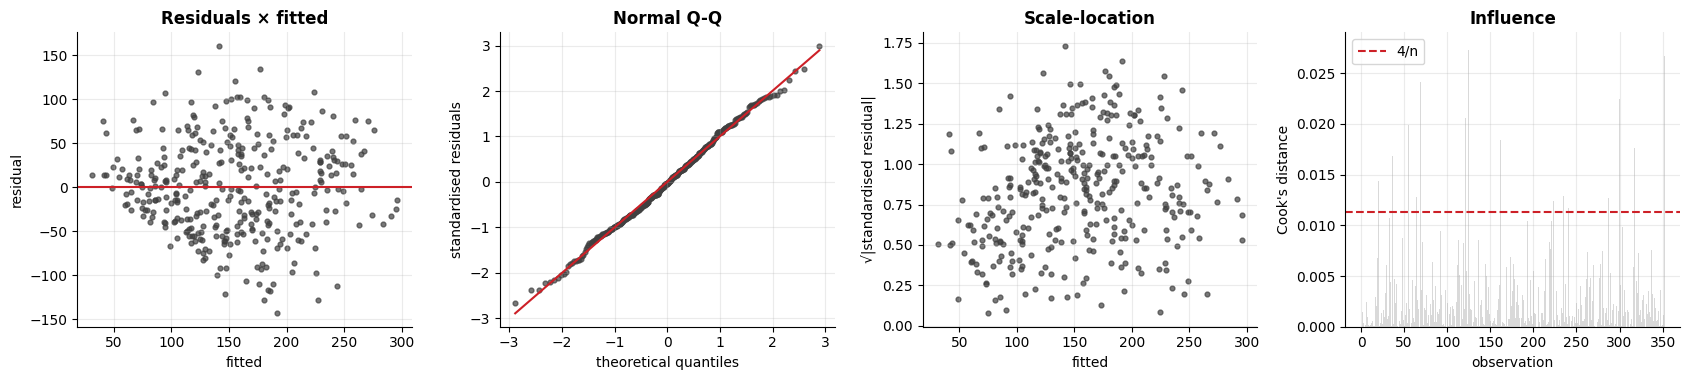

influential observations (Cook's D > 4/n): 18 of 353


In [8]:
#Diagnostic Plots: Residuals, Q-Q, Scale-Location and Cook's Distance
fitted = ols.A_ @ ols.beta_
std_res = ols.resid_ / np.sqrt(ols.s2_ * (1 - ols.leverage_))
cooks = std_res ** 2 / ols.p_ * ols.leverage_ / (1 - ols.leverage_)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
axes[0].scatter(fitted, ols.resid_, s=12, color=DARK, alpha=0.7); axes[0].axhline(0, color=RED); axes[0].set_xlabel("fitted"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals × fitted")
(th, ord_), (slope, icpt, _) = stats.probplot(std_res, dist="norm")
axes[1].scatter(th, ord_, s=12, color=DARK, alpha=0.7); axes[1].plot(th, slope * th + icpt, color=RED); axes[1].set_xlabel("theoretical quantiles"); axes[1].set_ylabel("standardised residuals"); axes[1].set_title("Normal Q-Q")
axes[2].scatter(fitted, np.sqrt(np.abs(std_res)), s=12, color=DARK, alpha=0.7); axes[2].set_xlabel("fitted"); axes[2].set_ylabel("√|standardised residual|"); axes[2].set_title("Scale-location")
axes[3].bar(range(len(cooks)), cooks, color=LIGHT, width=1.0); axes[3].axhline(4 / ols.n_, color=RED, ls="--", label="4/n"); axes[3].set_xlabel("observation"); axes[3].set_ylabel("Cook's distance"); axes[3].set_title("Influence"); axes[3].legend()
plt.tight_layout(); plt.show()
print("influential observations (Cook's D > 4/n):", int((cooks > 4 / ols.n_).sum()), "of", ols.n_)

,statistic,p-value,reading
normality,0.997,0.640,Shapiro-Wilk: residuals look normal
autocorrelation,1.794,NaN,Durbin-Watson ≈ 2: no autocorrelation
heteroscedasticity,19.484,0.035,Breusch-Pagan: evidence of non-constant varian...


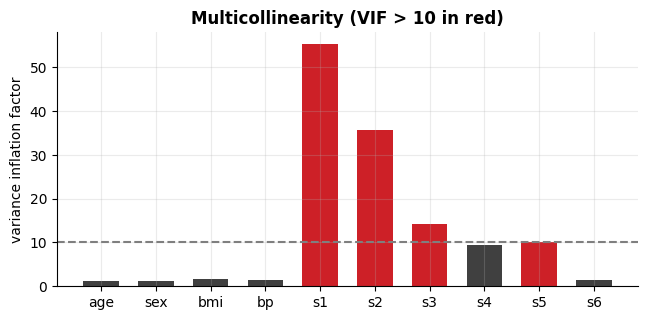

In [9]:
#Formal Tests: Normality, Autocorrelation and Heteroscedasticity, and Multicollinearity ( VIF )
res = ols.resid_
shapiro = stats.shapiro(res)
dw = np.sum(np.diff(res) ** 2) / np.sum(res ** 2)
aux = OLS().fit(Xd_tr, res ** 2)                                         # Breusch-Pagan: regress squared residuals on X
lm = ols.n_ * (1 - aux.sse_ / aux.sst_)
bp_p = stats.chi2.sf(lm, ols.p_ - 1)
reading = [("Shapiro-Wilk: residuals look normal" if shapiro.pvalue > 0.05 else "Shapiro-Wilk: normality rejected"),
           ("Durbin-Watson ≈ 2: no autocorrelation" if 1.5 < dw < 2.5 else "Durbin-Watson: possible autocorrelation"),
           ("Breusch-Pagan: no evidence against constant variance" if bp_p > 0.05 else "Breusch-Pagan: evidence of non-constant variance (p < 0.05)")]
tests = pd.DataFrame({"statistic": [shapiro.statistic, dw, lm], "p-value": [shapiro.pvalue, np.nan, bp_p], "reading": reading},
                     index=["normality", "autocorrelation", "heteroscedasticity"])
display(tests.round(4))

vif = {}
for c_ in Xd_tr.columns:
    others = Xd_tr.drop(columns=c_)
    r = OLS().fit(others, Xd_tr[c_])
    vif[c_] = 1 / (r.sse_ / r.sst_)
vif = pd.Series(vif, name="VIF")
plt.figure(figsize=(7.5, 3.3)); plt.bar(vif.index, vif.values, color=[RED if v > 10 else DARK for v in vif.values], width=0.65); plt.axhline(10, color=GRAY, ls="--")
plt.ylabel("variance inflation factor"); plt.title("Multicollinearity (VIF > 10 in red)"); plt.show()

Residuals are close to normal and uncorrelated; Breusch-Pagan hints at **mild heteroscedasticity**. Several attributes (`s1`, `s2`, `s3`…) are **strongly collinear** (VIF ≫ 10): their individual coefficients are unstable. **Regularisation** shrinks them.

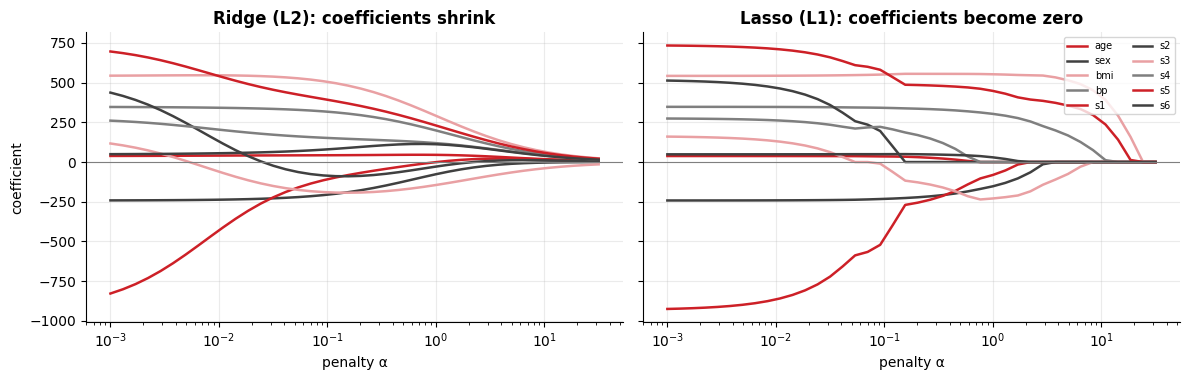

,model,test RMSE,test R²,non-zero coefficients
0,OLS,53.853,0.453,10
1,Ridge (α=0.084),53.468,0.460,10
2,Lasso (α=0.078),52.918,0.471,7


In [10]:
#Regularisation Paths ( Ridge and Lasso ) and Cross-Validated Choice of the Penalty
from sklearn.linear_model import Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler

alphas = np.logspace(-3, 1.5, 40)
ridge_path = np.array([Ridge(alpha=a).fit(Xd_tr, yd_tr).coef_ for a in alphas])
lasso_path = np.array([Lasso(alpha=a / 10, max_iter=100000).fit(Xd_tr, yd_tr).coef_ for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, path, title in zip(axes, [ridge_path, lasso_path], ["Ridge (L2): coefficients shrink", "Lasso (L1): coefficients become zero"]):
    for j, c_ in enumerate(Xd_tr.columns):
        ax.plot(alphas, path[:, j], lw=1.8, label=c_)
    ax.set_xscale("log"); ax.set_xlabel("penalty α"); ax.set_title(title); ax.axhline(0, color=GRAY, lw=0.8)
axes[0].set_ylabel("coefficient"); axes[1].legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

ridge_cv = RidgeCV(alphas=np.logspace(-3, 2, 40), cv=5).fit(Xd_tr, yd_tr)
lasso_cv = LassoCV(cv=5, max_iter=100000, random_state=RANDOM_STATE).fit(Xd_tr, yd_tr)
rows = [("OLS", np.sqrt(mean_squared_error(yd_te, ols.predict(Xd_te))), r2_score(yd_te, ols.predict(Xd_te)), 10),
        (f"Ridge (α={ridge_cv.alpha_:.2g})", np.sqrt(mean_squared_error(yd_te, ridge_cv.predict(Xd_te))), r2_score(yd_te, ridge_cv.predict(Xd_te)), 10),
        (f"Lasso (α={lasso_cv.alpha_:.2g})", np.sqrt(mean_squared_error(yd_te, lasso_cv.predict(Xd_te))), r2_score(yd_te, lasso_cv.predict(Xd_te)), int((lasso_cv.coef_ != 0).sum()))]
pd.DataFrame(rows, columns=["model", "test RMSE", "test R²", "non-zero coefficients"]).round(3)

#### **From Regression to Classification**

The same predictions can answer a **yes/no** question: *will the progression be above the median?* The predicted value is the **score**, so the generic classification metrics apply.

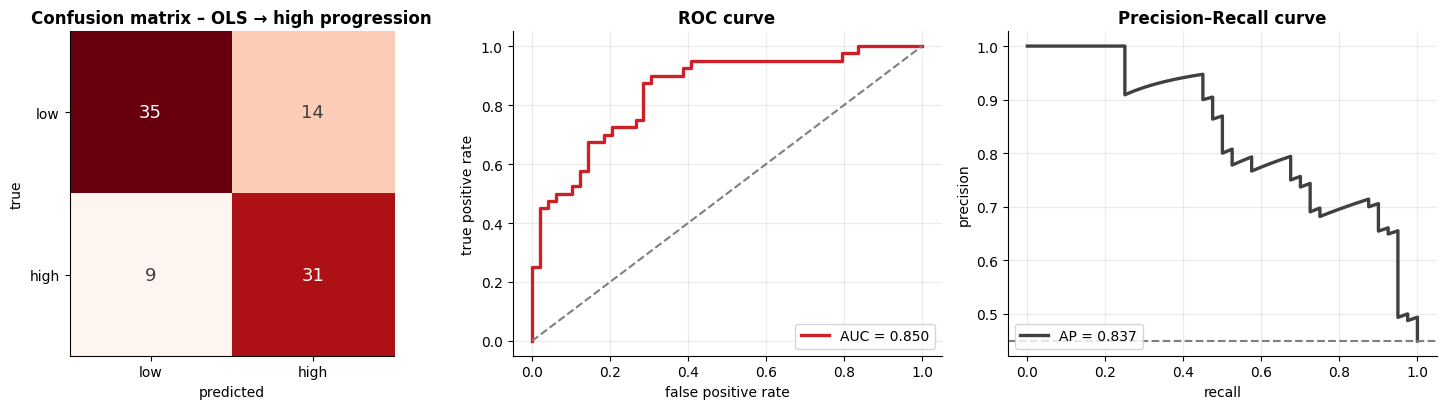

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
OLS → high progression,0.742,0.745,0.689,0.775,0.729,0.487,0.85,0.837


In [11]:
#Use the Regression Output as a Score for "High Progression" ( Confusion Matrix, ROC, Precision-Recall )
cut = yd_tr.median()
y_high = (yd_te > cut).astype(int).to_numpy()
report_binary(y_high, (pred_te > cut).astype(int), pred_te, "OLS → high progression", ["low", "high"]).to_frame().T

### **3. Logistic Regression**

Models the **probability** of the positive class through the logistic function:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta^T x)}} \qquad \log\frac{p}{1-p} = \beta_0 + \beta^T x$$

* $e^{\beta_j}$ is the **odds ratio** of attribute $j$
* Parameters by **maximum likelihood**: no closed form, solved by **IRLS / Newton–Raphson** (each step is a weighted least squares)

Data: **Breast Cancer** (positive class = malignant), 70/30 split.

In [12]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant )
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, (bc.target == 0).astype(int)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=RANDOM_STATE, stratify=yb)
CLASSES = ["benign", "malignant"]
print("train:", Xb_tr.shape, "| test:", Xb_te.shape, "| malignant in train:", f"{yb_tr.mean():.1%}")

train: (398, 30) | test: (171, 30) | malignant in train: 37.2%


In [13]:
#Logistic Regression by IRLS ( Newton–Raphson ) from Scratch with Standard Errors, Wald Tests and Odds Ratios
from scipy.special import expit

class LogisticIRLS:
    def fit(self, X, y, max_iter=50, tol=1e-10):
        A = np.c_[np.ones(len(X)), np.asarray(X, float)]
        y = np.asarray(y, float)
        self.names_ = ["intercept"] + list(X.columns)
        b, self.trace_ = np.zeros(A.shape[1]), []
        for it in range(max_iter):
            mu = expit(A @ b)
            W = mu * (1 - mu)
            H = A.T @ (A * W[:, None])                                    # Hessian (Fisher information)
            step = np.linalg.solve(H, A.T @ (y - mu))                      # weighted least-squares step
            b = b + step
            self.trace_.append(self._loglik(A, y, b))
            if np.abs(step).max() < tol:
                break
        self.beta_, self.cov_, self.n_iter_ = b, np.linalg.inv(H), it + 1
        self.A_, self.y_ = A, y
        return self

    @staticmethod
    def _loglik(A, y, b):
        eta = A @ b
        return float(np.sum(y * eta - np.logaddexp(0, eta)))

    def predict_proba(self, X):
        return expit(np.c_[np.ones(len(X)), np.asarray(X, float)] @ self.beta_)

    def summary(self):
        se = np.sqrt(np.diag(self.cov_)); z = self.beta_ / se
        return pd.DataFrame({"coef": self.beta_, "std err": se, "z": z, "p-value": 2 * stats.norm.sf(np.abs(z)),
                             "odds ratio": np.exp(self.beta_), "OR low": np.exp(self.beta_ - 1.96 * se), "OR high": np.exp(self.beta_ + 1.96 * se)}, index=self.names_)

    def fit_stats(self):
        ll, p = self.trace_[-1], self.y_.mean()
        ll0 = float(np.sum(self.y_ * np.log(p) + (1 - self.y_) * np.log(1 - p)))
        k, n = len(self.beta_), len(self.y_)
        lr = 2 * (ll - ll0)
        return {"log-likelihood": ll, "null log-likelihood": ll0, "McFadden R²": 1 - ll / ll0, "LR statistic": lr, "LR p-value": stats.chi2.sf(lr, k - 1),
                "AIC": 2 * k - 2 * ll, "BIC": k * np.log(n) - 2 * ll, "IRLS iterations": self.n_iter_}

inference_cols = ["mean radius", "mean texture", "mean smoothness", "mean compactness", "mean symmetry", "mean fractal dimension"]
sc_inf = StandardScaler().fit(Xb_tr[inference_cols])
Zb_tr = pd.DataFrame(sc_inf.transform(Xb_tr[inference_cols]), columns=inference_cols, index=Xb_tr.index)
Zb_te = pd.DataFrame(sc_inf.transform(Xb_te[inference_cols]), columns=inference_cols, index=Xb_te.index)

irls = LogisticIRLS().fit(Zb_tr, yb_tr)
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1e12, solver="newton-cholesky", tol=1e-12, max_iter=200).fit(Zb_tr, yb_tr)          # (almost) unpenalised Newton solver
print("IRLS iterations:", irls.n_iter_, "| max |coefficient difference| to scikit-learn:", f"{np.abs(irls.beta_[1:] - sk.coef_[0]).max():.1e}")
irls.summary().round(3)

IRLS iterations: 10 | max |coefficient difference| to scikit-learn: 4.4e-12


,coef,std err,z,p-value,odds ratio,OR low,OR high
intercept,-1.034,0.262,-3.951,0.000,0.356,0.213,0.594
mean radius,5.014,0.912,5.498,0.000,150.566,25.195,899.790
mean texture,1.753,0.336,5.211,0.000,5.773,2.986,11.163
mean smoothness,1.568,0.411,3.818,0.000,4.798,2.145,10.729
mean compactness,0.519,0.715,0.727,0.468,1.681,0.414,6.821
mean symmetry,0.604,0.329,1.837,0.066,1.829,0.960,3.485
mean fractal dimension,0.116,0.673,0.173,0.863,1.123,0.300,4.205


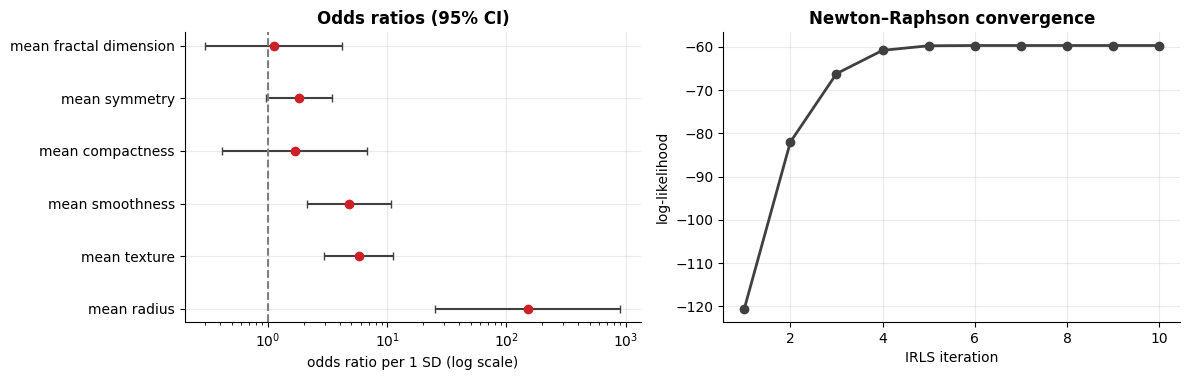

,log-likelihood,null log-likelihood,McFadden R²,LR statistic,LR p-value,AIC,BIC,IRLS iterations
value,-59.715,-262.655,0.773,405.881,0.0,133.429,161.334,10.0


In [14]:
#Odds Ratios with 95% Confidence Intervals, Convergence of the Likelihood and Global Fit Statistics
sm = irls.summary().iloc[1:]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
yy = np.arange(len(sm))
axes[0].errorbar(sm["odds ratio"], yy, xerr=[sm["odds ratio"] - sm["OR low"], sm["OR high"] - sm["odds ratio"]], fmt="o", color=RED, ecolor=DARK, capsize=3)
axes[0].axvline(1, color=GRAY, ls="--"); axes[0].set_yticks(yy); axes[0].set_yticklabels(sm.index); axes[0].set_xscale("log"); axes[0].set_xlabel("odds ratio per 1 SD (log scale)"); axes[0].set_title("Odds ratios (95% CI)")
axes[1].plot(range(1, len(irls.trace_) + 1), irls.trace_, marker="o", color=DARK, lw=2); axes[1].set_xlabel("IRLS iteration"); axes[1].set_ylabel("log-likelihood"); axes[1].set_title("Newton–Raphson convergence")
plt.tight_layout(); plt.show()
pd.Series(irls.fit_stats()).to_frame("value").T.round(3)

Interpretation: `mean texture` has an odds ratio of ≈ **5.8**: **one more standard deviation** multiplies the odds of malignancy by ≈ 5.8, other attributes fixed. `mean radius` has a huge but **imprecise** estimate (very wide interval). Intervals that **cross 1** (compactness, symmetry, fractal dimension) are not significant.

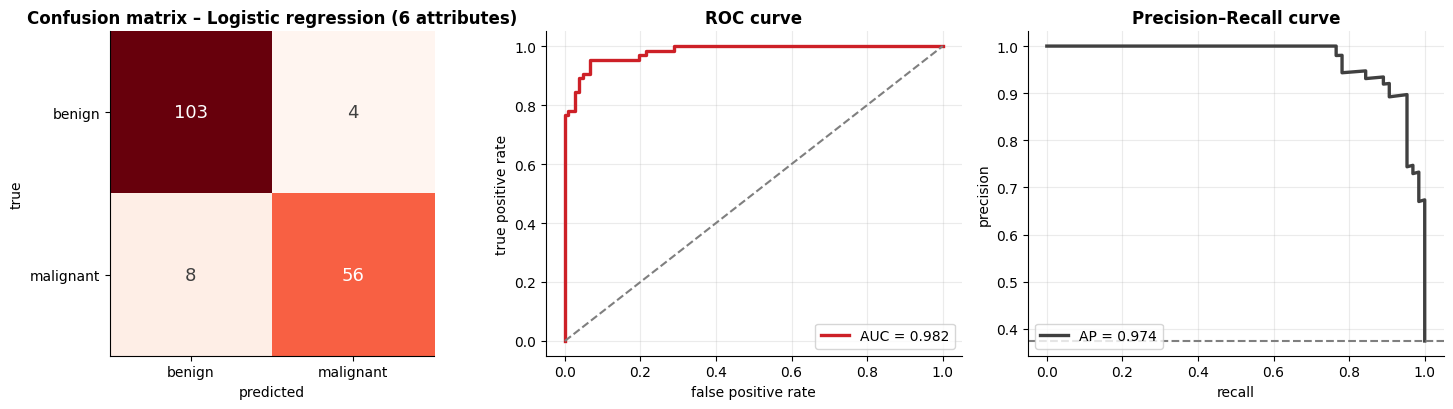

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Logistic regression (6 attributes),0.93,0.919,0.933,0.875,0.903,0.849,0.982,0.974


In [15]:
#Evaluate the Inference Model ( 6 Attributes ) on the Test Set
results_lr = {}
proba_irls = irls.predict_proba(Zb_te)
results_lr["IRLS (6 attributes)"] = report_binary(yb_te, (proba_irls >= 0.5).astype(int), proba_irls, "Logistic regression (6 attributes)", CLASSES)
results_lr["IRLS (6 attributes)"].to_frame().T

#### **A Predictive Model with All the 30 Attributes**

With 30 correlated attributes the unpenalised fit **overfits** (and may not even converge). **L2 regularisation** (`C` = inverse of the penalty) fixes it.

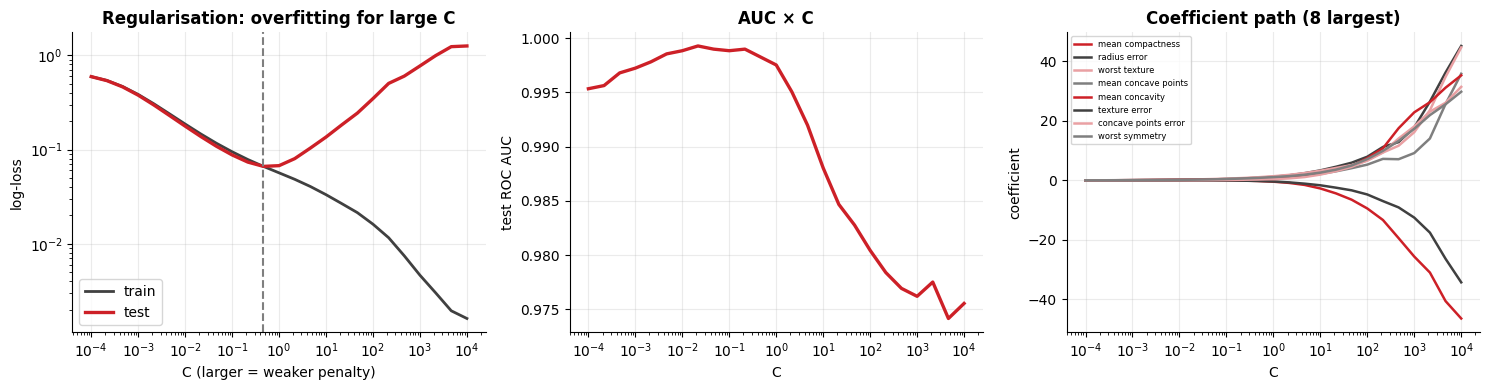

best C by test log-loss: 0.464


In [16]:
#Regularisation Path: Train × Test Log-Loss and Coefficients as a Function of C ( L2 )
from sklearn.pipeline import make_pipeline

Cs = np.logspace(-4, 4, 25)
tr_ll, te_ll, te_auc, coefs = [], [], [], []
for c_ in Cs:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=c_, max_iter=20000)).fit(Xb_tr, yb_tr)
    tr_ll.append(log_loss(yb_tr, m.predict_proba(Xb_tr)[:, 1])); te_ll.append(log_loss(yb_te, m.predict_proba(Xb_te)[:, 1]))
    te_auc.append(roc_auc_score(yb_te, m.predict_proba(Xb_te)[:, 1])); coefs.append(m[-1].coef_[0])
best_C = Cs[int(np.argmin(te_ll))]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(Cs, tr_ll, color=DARK, lw=2, label="train"); axes[0].plot(Cs, te_ll, color=RED, lw=2.4, label="test"); axes[0].axvline(best_C, color=GRAY, ls="--")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("C (larger = weaker penalty)"); axes[0].set_ylabel("log-loss"); axes[0].set_title("Regularisation: overfitting for large C"); axes[0].legend()
axes[1].plot(Cs, te_auc, color=RED, lw=2.4); axes[1].set_xscale("log"); axes[1].set_xlabel("C"); axes[1].set_ylabel("test ROC AUC"); axes[1].set_title("AUC × C")
coefs = np.array(coefs)
for j in np.argsort(-np.abs(coefs[-1]))[:8]:
    axes[2].plot(Cs, coefs[:, j], lw=1.8, label=Xb.columns[j])
axes[2].set_xscale("log"); axes[2].set_xlabel("C"); axes[2].set_ylabel("coefficient"); axes[2].set_title("Coefficient path (8 largest)"); axes[2].legend(fontsize=6)
plt.tight_layout(); plt.show()
print(f"best C by test log-loss: {best_C:.3g}")

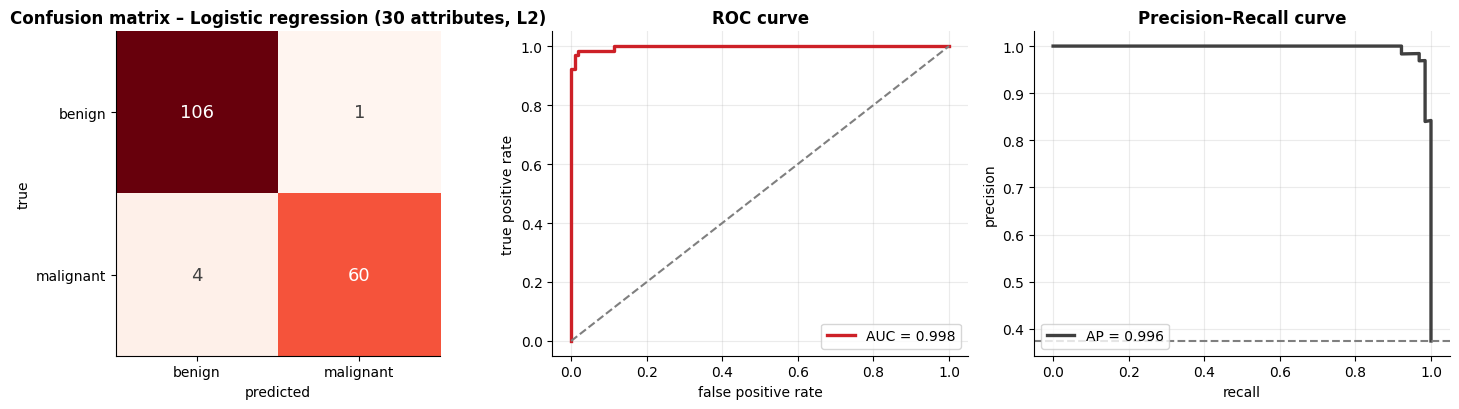

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
"Logistic regression (30 attributes, L2)",0.971,0.964,0.984,0.938,0.96,0.938,0.998,0.996


In [17]:
#Evaluate the Regularised Model ( All 30 Attributes ) with the Generic Metrics
final_lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=20000)).fit(Xb_tr, yb_tr)
proba_lr = final_lr.predict_proba(Xb_te)[:, 1]
results_lr["L2 (30 attributes)"] = report_binary(yb_te, (proba_lr >= 0.5).astype(int), proba_lr, "Logistic regression (30 attributes, L2)", CLASSES)
results_lr["L2 (30 attributes)"].to_frame().T

#### **Logistic-Regression-Specific Metrics**

**Probability quality:** log-loss, **Brier score** and the **calibration curve** · **Discrimination:** **KS** and **Gini** · **Goodness of fit:** Hosmer–Lemeshow · **Decision:** the choice of the **threshold**.

,log-loss,Brier score,KS statistic,Gini (2·AUC − 1),Hosmer-Lemeshow χ²,Hosmer-Lemeshow p
L2 logistic regression,0.068,0.019,0.966,0.995,2.158,0.976


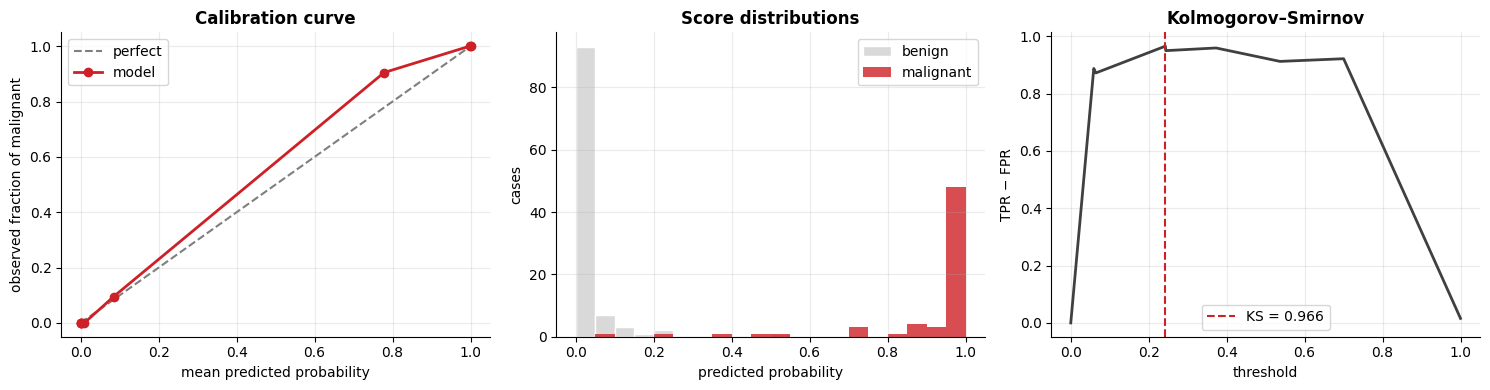

In [18]:
#Calibration Curve, Hosmer–Lemeshow Test, KS, Gini, Brier Score and Log-Loss
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def hosmer_lemeshow(y, p, groups=10):
    order = np.argsort(p)
    stat, used = 0.0, 0
    for idx in np.array_split(order, groups):
        o1, e1, n_g = y[idx].sum(), p[idx].sum(), len(idx)
        if 0 < e1 < n_g:
            stat += (o1 - e1) ** 2 / (e1 * (1 - e1 / n_g)); used += 1
    return stat, stats.chi2.sf(stat, used - 2)

y_np = yb_te.to_numpy()
hl, hl_p = hosmer_lemeshow(y_np, proba_lr)
fpr, tpr, thr = roc_curve(y_np, proba_lr)
ks = float(np.max(tpr - fpr))
specific = pd.Series({"log-loss": log_loss(y_np, proba_lr), "Brier score": brier_score_loss(y_np, proba_lr), "KS statistic": ks,
                      "Gini (2·AUC − 1)": 2 * roc_auc_score(y_np, proba_lr) - 1, "Hosmer-Lemeshow χ²": hl, "Hosmer-Lemeshow p": hl_p}, name="L2 logistic regression")
display(specific.to_frame().T.round(4))

frac_pos, mean_pred = calibration_curve(y_np, proba_lr, n_bins=8, strategy="quantile")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", label="perfect"); axes[0].plot(mean_pred, frac_pos, marker="o", color=RED, lw=2, label="model")
axes[0].set_xlabel("mean predicted probability"); axes[0].set_ylabel("observed fraction of malignant"); axes[0].set_title("Calibration curve"); axes[0].legend()
axes[1].hist(proba_lr[y_np == 0], bins=20, range=(0, 1), color=LIGHT, edgecolor="white", label="benign"); axes[1].hist(proba_lr[y_np == 1], bins=20, range=(0, 1), color=RED, alpha=0.8, label="malignant")
axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("cases"); axes[1].set_title("Score distributions"); axes[1].legend()
axes[2].plot(thr[1:], (tpr - fpr)[1:], color=DARK, lw=2); axes[2].axvline(thr[np.argmax(tpr - fpr)], color=RED, ls="--", label=f"KS = {ks:.3f}"); axes[2].set_xlabel("threshold"); axes[2].set_ylabel("TPR − FPR"); axes[2].set_title("Kolmogorov–Smirnov"); axes[2].legend()
plt.tight_layout(); plt.show()

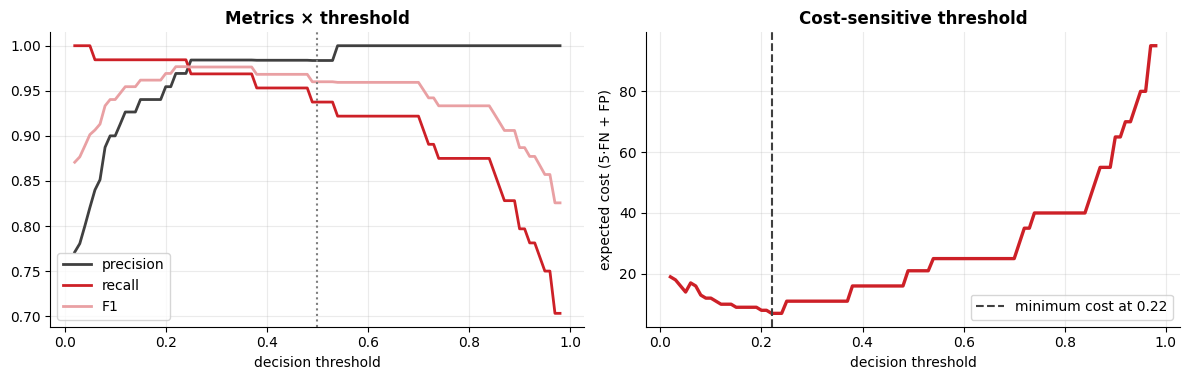

threshold with the best F1: 0.22 | Youden (KS): 0.24 | minimum cost: 0.22


In [19]:
#Threshold Choice: Precision, Recall, F1 and Expected Cost ( a Missed Malignant Case Costs 5x a False Alarm )
thresholds = np.linspace(0.02, 0.98, 97)
rows = []
for t in thresholds:
    pred = (proba_lr >= t).astype(int)
    tp = ((pred == 1) & (y_np == 1)).sum(); fp = ((pred == 1) & (y_np == 0)).sum(); fn = ((pred == 0) & (y_np == 1)).sum()
    rows.append({"threshold": t, "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn), "cost": 5 * fn + 1 * fp})
th = pd.DataFrame(rows)
t_cost, t_f1, t_youden = th.loc[th["cost"].idxmin(), "threshold"], th.loc[th["F1"].idxmax(), "threshold"], thr[np.argmax(tpr - fpr)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for col, color in zip(["precision", "recall", "F1"], [DARK, RED, SOFT]):
    axes[0].plot(th["threshold"], th[col], color=color, lw=2, label=col)
axes[0].axvline(0.5, color=GRAY, ls=":"); axes[0].set_xlabel("decision threshold"); axes[0].set_title("Metrics × threshold"); axes[0].legend()
axes[1].plot(th["threshold"], th["cost"], color=RED, lw=2.4); axes[1].axvline(t_cost, color=DARK, ls="--", label=f"minimum cost at {t_cost:.2f}"); axes[1].set_xlabel("decision threshold"); axes[1].set_ylabel("expected cost (5·FN + FP)"); axes[1].set_title("Cost-sensitive threshold"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"threshold with the best F1: {t_f1:.2f} | Youden (KS): {t_youden:.2f} | minimum cost: {t_cost:.2f}")

### **4. Bayesian Networks**

A **directed acyclic graph** whose nodes are random variables; the joint distribution **factorises** along the graph:

$$P(X_1, \dots, X_n) = \prod_i P\big(X_i \mid \text{Parents}(X_i)\big)$$

Each node has a **conditional probability table (CPT)**. We implement for **discrete** variables:

* **Parameter learning:** CPTs by counting (with **Laplace** smoothing)
* **Exact inference:** any $P(\text{query} \mid \text{evidence})$ by enumeration
* **Structure learning:** **hill-climbing** that maximises the **BIC** (add, remove or reverse edges)

First a **known** network (to measure how well we recover it), then a **classifier**.

In [20]:
#The True Network ( Medical Example ): Pollution, Smoker -> Cancer;  Smoker -> Bronchitis;  Cancer -> X-ray;  Cancer, Bronchitis -> Dyspnoea
import itertools
import networkx as nx

NAMES = ["Pollution", "Smoker", "Cancer", "Bronchitis", "XRay", "Dyspnoea"]
IDX = {n: i for i, n in enumerate(NAMES)}
TRUE_EDGES = {("Pollution", "Cancer"), ("Smoker", "Cancer"), ("Smoker", "Bronchitis"), ("Cancer", "XRay"), ("Cancer", "Dyspnoea"), ("Bronchitis", "Dyspnoea")}
# P(node = 1 | parents), parents in the order listed
TRUE_CPD = {
    "Pollution":  ((), {(): 0.30}),
    "Smoker":     ((), {(): 0.30}),
    "Cancer":     (("Pollution", "Smoker"), {(0, 0): 0.02, (1, 0): 0.25, (0, 1): 0.30, (1, 1): 0.70}),
    "Bronchitis": (("Smoker",), {(0,): 0.10, (1,): 0.60}),
    "XRay":       (("Cancer",), {(0,): 0.05, (1,): 0.92}),
    "Dyspnoea":   (("Cancer", "Bronchitis"), {(0, 0): 0.05, (0, 1): 0.70, (1, 0): 0.75, (1, 1): 0.95}),
}

def sample_true(n, seed):
    rng = np.random.default_rng(seed)
    D = np.zeros((n, len(NAMES)), dtype=int)
    for node in NAMES:                                                        # ancestral sampling (NAMES is in topological order)
        pa, cpd = TRUE_CPD[node]
        p1 = np.array([cpd[tuple(row)] for row in D[:, [IDX[p] for p in pa]]]) if pa else np.full(n, cpd[()])
        D[:, IDX[node]] = rng.random(n) < p1
    return D

D_all = sample_true(6000, seed=RANDOM_STATE)
D_train, D_test = D_all[:5000], D_all[5000:]
cards = [2] * len(NAMES)
print("samples:", D_train.shape, "| marginal P(1):", {n: round(float(v), 3) for n, v in zip(NAMES, D_train.mean(axis=0))})

samples: (5000, 6) | marginal P(1): {'Pollution': 0.308, 'Smoker': 0.295, 'Cancer': 0.191, 'Bronchitis': 0.244, 'XRay': 0.217, 'Dyspnoea': 0.3}


In [21]:
#Discrete Bayesian Network: Parameter Learning, Log-Likelihood, BIC, Exact Inference and Structure Scores
def count_table(D, v, pa, cards):
    cfg = np.zeros(len(D), dtype=int)
    for p in pa:
        cfg = cfg * cards[p] + D[:, p]
    n_cfg = int(np.prod([cards[p] for p in pa])) if pa else 1
    return np.bincount(cfg * cards[v] + D[:, v], minlength=n_cfg * cards[v]).reshape(n_cfg, cards[v])

def local_bic(D, v, pa, cards):
    """Decomposable BIC score of one node: log-likelihood − ½ · ln(N) · (number of free parameters)."""
    cnt = count_table(D, v, pa, cards)
    row = cnt.sum(axis=1, keepdims=True)
    nz = cnt > 0
    ll = (cnt[nz] * np.log((cnt / np.where(row == 0, 1, row))[nz])).sum()
    return ll - 0.5 * np.log(len(D)) * cnt.shape[0] * (cards[v] - 1)

class DiscreteBN:
    def __init__(self, parents, cards, alpha=1.0):
        self.parents, self.cards, self.alpha = {v: tuple(p) for v, p in parents.items()}, list(cards), alpha

    def fit(self, D):
        self.cpt_ = {}
        for v, pa in self.parents.items():
            cnt = count_table(D, v, pa, self.cards) + self.alpha                      # Laplace smoothing
            self.cpt_[v] = cnt / cnt.sum(axis=1, keepdims=True)
        return self

    def _cfg(self, D, pa):
        cfg = np.zeros(len(D), dtype=int)
        for p in pa:
            cfg = cfg * self.cards[p] + D[:, p]
        return cfg

    def log_joint(self, D):                                                           # log P(x) for every row
        return sum(np.log(self.cpt_[v][self._cfg(D, pa), D[:, v]]) for v, pa in self.parents.items())

    def loglik(self, D):
        return float(self.log_joint(D).sum())

    def bic(self, D):
        return sum(local_bic(D, v, pa, self.cards) for v, pa in self.parents.items())

    def joint_table(self):                                                            # full joint over all states (small networks)
        states = np.array(list(itertools.product(*[range(c) for c in self.cards])))
        return states, np.exp(self.log_joint(states))

    def query(self, target, evidence):
        """Exact inference by enumeration: P(target | evidence) as a vector."""
        states, prob = self.joint_table()
        keep = np.ones(len(states), bool)
        for v, val in evidence.items():
            keep &= states[:, v] == val
        post = np.array([prob[keep & (states[:, target] == s)].sum() for s in range(self.cards[target])])
        return post / post.sum()

    def posterior_binary(self, D, target):                                           # P(target=1 | all other variables) for each row
        D2, lj = D.copy(), []
        for s in (0, 1):
            D2[:, target] = s
            lj.append(self.log_joint(D2))
        return 1 / (1 + np.exp(lj[0] - lj[1]))

true_parents = {IDX[n]: tuple(IDX[p] for p in TRUE_CPD[n][0]) for n in NAMES}
bn_true = DiscreteBN(true_parents, cards).fit(D_train)                               # true structure, learned parameters
print("log-likelihood (test):", round(bn_true.loglik(D_test), 1), "| BIC (train):", round(bn_true.bic(D_train), 1))

log-likelihood (test): -2581.6 | BIC (train): -12736.2


#### **Parameter Learning**

How close are the **learned CPTs** to the true ones as the sample grows? Metric: **KL divergence** between the true joint distribution and the learned one (20 replicates per size).

true joint sums to 1.0 over 64 states


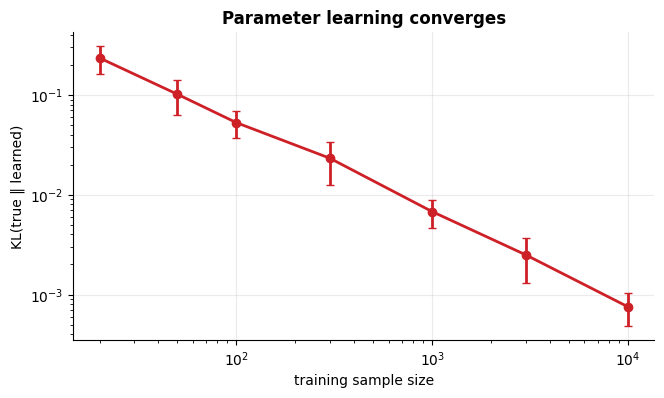

In [22]:
#Parameter Learning: KL Divergence to the True Joint Distribution as a Function of the Sample Size
true_bn = DiscreteBN(true_parents, cards)
true_bn.cpt_ = {IDX[n]: np.array([[1 - TRUE_CPD[n][1][k], TRUE_CPD[n][1][k]] for k in sorted(TRUE_CPD[n][1])]) for n in NAMES}
states, p_true = true_bn.joint_table()
print("true joint sums to", round(p_true.sum(), 6), "over", len(states), "states")

sizes = [20, 50, 100, 300, 1000, 3000, 10000]
kl = {n: [] for n in sizes}
for n in sizes:
    for rep in range(20):
        learned = DiscreteBN(true_parents, cards).fit(sample_true(n, seed=1000 + rep))
        p_hat = learned.joint_table()[1]
        kl[n].append(float((p_true * np.log(p_true / p_hat)).sum()))
kl_df = pd.DataFrame(kl)

plt.figure(figsize=(7.5, 4))
plt.errorbar(sizes, kl_df.mean(), yerr=kl_df.std(), marker="o", color=RED, lw=2, capsize=3)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("training sample size"); plt.ylabel("KL(true ‖ learned)"); plt.title("Parameter learning converges")
plt.show()

#### **Exact Inference**

Any conditional probability can be computed, in **any direction** (causes → effects, or effects → causes).

In [23]:
#Exact Inference by Enumeration ( Including the "Explaining Away" Effect )
def q(target, **evidence):
    return bn_true.query(IDX[target], {IDX[k]: v for k, v in evidence.items()})[1]

queries = pd.DataFrame([
    ("P(Cancer)",                                          q("Cancer")),
    ("P(Cancer | Smoker=1)",                               q("Cancer", Smoker=1)),
    ("P(Cancer | Smoker=1, XRay=1)",                       q("Cancer", Smoker=1, XRay=1)),
    ("P(Cancer | XRay=1, Dyspnoea=1)",                     q("Cancer", XRay=1, Dyspnoea=1)),
    ("P(Pollution | Cancer=1)",                            q("Pollution", Cancer=1)),
    ("P(Pollution | Cancer=1, Smoker=1)  ← explaining away", q("Pollution", Cancer=1, Smoker=1)),
], columns=["query", "probability"])
queries["probability"] = queries["probability"].round(4)
queries

,query,probability
0,P(Cancer),0.193
1,P(Cancer | Smoker=1),0.423
2,"P(Cancer | Smoker=1, XRay=1)",0.931
3,"P(Cancer | XRay=1, Dyspnoea=1)",0.953
4,P(Pollution | Cancer=1),0.649
5,"P(Pollution | Cancer=1, Smoker=1) ← explainin...",0.532


Learning that the patient **smokes** *explains* the cancer, so the probability that **pollution** was the cause **drops** (≈ 0.65 → 0.53 in the table): the **explaining-away** effect of a *v-structure*.

#### **Structure Learning (Hill-Climbing + BIC)**

Start with **no edges** and apply, at each step, the move (add / remove / reverse an edge) that **most improves the BIC**, keeping the graph **acyclic**.
The greedy search can get **trapped in a local optimum**, so we also climb from **random DAGs** and keep the best BIC.

In [24]:
#Hill-Climbing Structure Search with the BIC Score ( Add, Remove or Reverse Edges ) and Restarts from Random DAGs
def hill_climb(D, cards, max_parents=3, max_iter=100, init=None, cache=None):
    V = D.shape[1]
    parents = {v: frozenset(init[v]) if init else frozenset() for v in range(V)}
    G = nx.DiGraph(); G.add_nodes_from(range(V)); G.add_edges_from((u, v) for v, pa in parents.items() for u in pa)
    cache = {} if cache is None else cache

    def local(v, pa):
        key = (v, pa)
        if key not in cache:
            cache[key] = local_bic(D, v, tuple(sorted(pa)), cards)
        return cache[key]

    history = [sum(local(v, parents[v]) for v in range(V))]
    for _ in range(max_iter):
        best_delta, best_move = 1e-9, None
        for u in range(V):
            for v in range(V):
                if u == v:
                    continue
                if G.has_edge(u, v):
                    d = local(v, parents[v] - {u}) - local(v, parents[v])
                    if d > best_delta:
                        best_delta, best_move = d, ("remove", u, v)
                    if len(parents[u]) < max_parents:                                                    # reverse u->v into v->u
                        G.remove_edge(u, v)
                        acyclic = not nx.has_path(G, u, v)
                        G.add_edge(u, v)
                        d2 = d + local(u, parents[u] | {v}) - local(u, parents[u])
                        if acyclic and d2 > best_delta:
                            best_delta, best_move = d2, ("reverse", u, v)
                elif len(parents[v]) < max_parents and not nx.has_path(G, v, u):
                    d = local(v, parents[v] | {u}) - local(v, parents[v])
                    if d > best_delta:
                        best_delta, best_move = d, ("add", u, v)
        if best_move is None:
            break
        kind, u, v = best_move
        if kind == "add":
            G.add_edge(u, v); parents[v] = parents[v] | {u}
        elif kind == "remove":
            G.remove_edge(u, v); parents[v] = parents[v] - {u}
        else:
            G.remove_edge(u, v); G.add_edge(v, u); parents[v] = parents[v] - {u}; parents[u] = parents[u] | {v}
        history.append(history[-1] + best_delta)
    return {v: tuple(sorted(p)) for v, p in parents.items()}, history

def random_dag(V, rng, p_edge=0.35, max_parents=3):
    order, parents = rng.permutation(V), {v: [] for v in range(V)}
    for i in range(V):
        for j in range(i + 1, V):
            if rng.random() < p_edge and len(parents[order[j]]) < max_parents:
                parents[order[j]].append(int(order[i]))
    return {v: tuple(p) for v, p in parents.items()}

def hill_climb_restarts(D, cards, n_restarts=25, max_parents=3, seed=0):
    """Greedy search from the empty graph, plus climbs started from random DAGs; keeps the best BIC found."""
    rng, cache = np.random.default_rng(seed), {}
    best, hist = hill_climb(D, cards, max_parents, cache=cache)
    best_score = hist[-1]
    for _ in range(n_restarts):
        cand, h = hill_climb(D, cards, max_parents, init=random_dag(D.shape[1], rng, max_parents=max_parents), cache=cache)
        if h[-1] > best_score + 1e-9:
            best, best_score = cand, h[-1]
    return best, hist, best_score

def compare_structures(true_edges, learned_edges):
    tp = len(true_edges & learned_edges)
    prec, rec = tp / max(len(learned_edges), 1), tp / len(true_edges)
    und = lambda E: {frozenset(e) for e in E}
    tps = len(und(true_edges) & und(learned_edges))
    pairs = {frozenset(e) for e in true_edges | learned_edges}
    shd = sum(1 for p in pairs if {e for e in true_edges if frozenset(e) == p} != {e for e in learned_edges if frozenset(e) == p})
    return {"edge precision": prec, "edge recall": rec, "edge F1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            "skeleton F1": 2 * tps / (len(und(true_edges)) + len(und(learned_edges))), "SHD": shd}

greedy_parents, bic_history = hill_climb(D_train, cards)
learned_parents, _, best_bic = hill_climb_restarts(D_train, cards)
edges_of = lambda pa: {(NAMES[u], NAMES[v]) for v, p in pa.items() for u in p}
learned_edges, greedy_edges = edges_of(learned_parents), edges_of(greedy_parents)
rows = {"greedy (empty start)": {"BIC": bic_history[-1], **compare_structures(TRUE_EDGES, greedy_edges)},
        "with 25 random restarts": {"BIC": best_bic, **compare_structures(TRUE_EDGES, learned_edges)},
        "true structure": {"BIC": bn_true.bic(D_train), **compare_structures(TRUE_EDGES, TRUE_EDGES)}}
print("edges (restarts):", sorted(learned_edges))
pd.DataFrame(rows).T.round(3)

edges (restarts): [('Bronchitis', 'Dyspnoea'), ('Cancer', 'Dyspnoea'), ('Cancer', 'XRay'), ('Pollution', 'Cancer'), ('Smoker', 'Bronchitis'), ('Smoker', 'Cancer')]


,BIC,edge precision,edge recall,edge F1,skeleton F1,SHD
greedy (empty start),-12738.936,0.429,0.5,0.462,0.923,4.0
with 25 random restarts,-12736.164,1.000,1.0,1.000,1.000,0.0
true structure,-12736.164,1.000,1.0,1.000,1.000,0.0


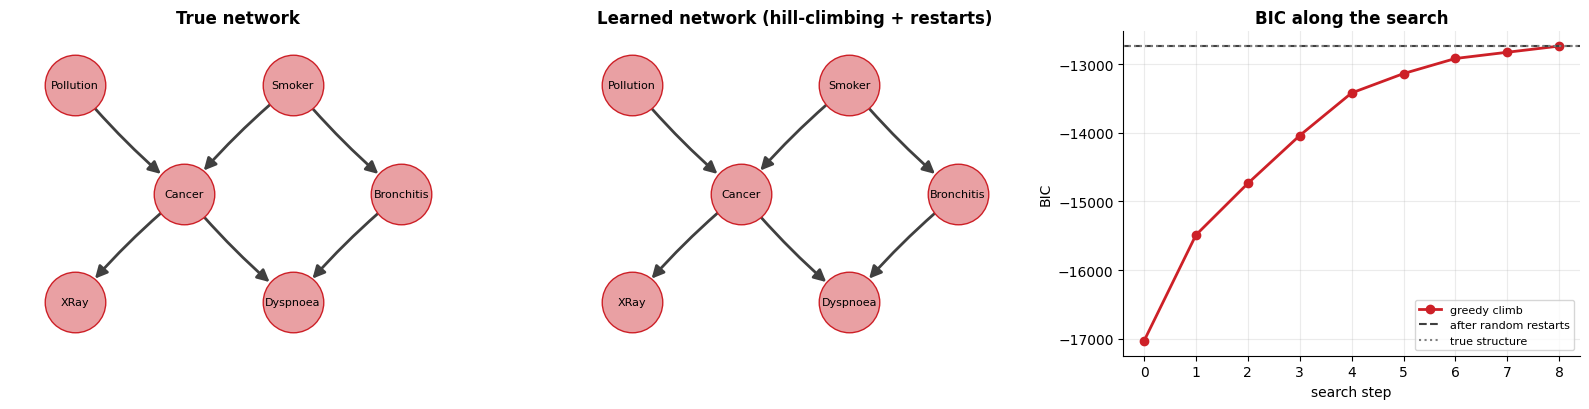

red edges = not in the true network (wrong or reversed; reversed edges can be Markov-equivalent)


In [25]:
#Compare the True and the Learned Graphs, and the BIC Along the Search
pos = {"Pollution": (0, 2), "Smoker": (2, 2), "Cancer": (1, 1), "Bronchitis": (3, 1), "XRay": (0, 0), "Dyspnoea": (2, 0)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, edges, title in [(axes[0], TRUE_EDGES, "True network"), (axes[1], learned_edges, "Learned network (hill-climbing + restarts)")]:
    Gd = nx.DiGraph(); Gd.add_nodes_from(NAMES); Gd.add_edges_from(edges)
    colors = [DARK if e in TRUE_EDGES else RED for e in Gd.edges]
    nx.draw_networkx(Gd, pos, ax=ax, node_color=SOFT, edgecolors=RED, node_size=1900, font_size=8, edge_color=colors, width=2, arrowsize=18, connectionstyle="arc3,rad=0.05")
    ax.set_title(title); ax.axis("off"); ax.set_xlim(-0.6, 3.6); ax.set_ylim(-0.5, 2.5)
axes[2].plot(bic_history, marker="o", color=RED, lw=2, label="greedy climb"); axes[2].axhline(best_bic, color=DARK, ls="--", label="after random restarts"); axes[2].axhline(bn_true.bic(D_train), color=GRAY, ls=":", label="true structure")
axes[2].set_xlabel("search step"); axes[2].set_ylabel("BIC"); axes[2].set_title("BIC along the search"); axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print("red edges = not in the true network (wrong or reversed; reversed edges can be Markov-equivalent)")

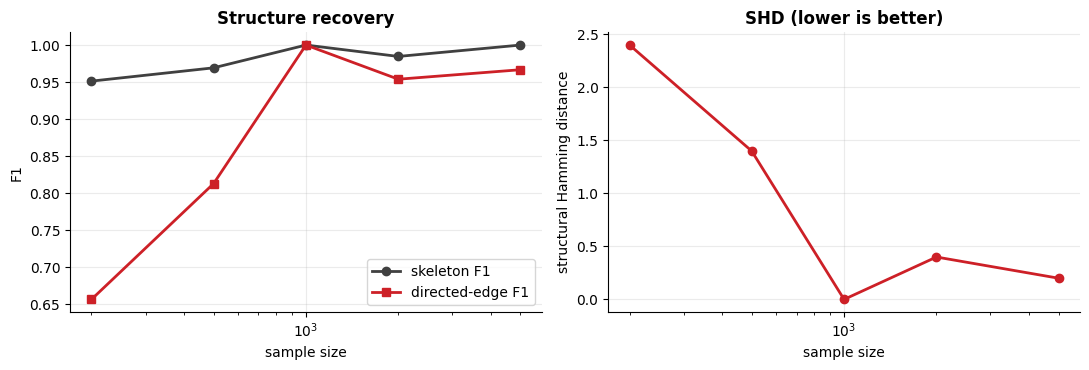

,edge precision,edge recall,edge F1,skeleton F1,SHD
N,,,,,
200,0.648,0.667,0.656,0.951,2.4
500,0.795,0.833,0.813,0.969,1.4
1000,1.000,1.000,1.000,1.000,0.0
2000,0.943,0.967,0.954,0.985,0.4
5000,0.967,0.967,0.967,1.000,0.2


In [26]:
#Structure Recovery as a Function of the Sample Size ( 5 Replicates per Size )
rows = []
for n in [200, 500, 1000, 2000, 5000]:
    for rep in range(5):
        D_n = sample_true(n, seed=500 + rep)
        pa, _, _ = hill_climb_restarts(D_n, cards, n_restarts=15, seed=rep)
        e = {(NAMES[u], NAMES[v]) for v, p in pa.items() for u in p}
        rows.append({"N": n, **compare_structures(TRUE_EDGES, e)})
rec = pd.DataFrame(rows).groupby("N").mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(rec.index, rec["skeleton F1"], marker="o", color=DARK, lw=2, label="skeleton F1"); axes[0].plot(rec.index, rec["edge F1"], marker="s", color=RED, lw=2, label="directed-edge F1")
axes[0].set_xscale("log"); axes[0].set_xlabel("sample size"); axes[0].set_ylabel("F1"); axes[0].set_title("Structure recovery"); axes[0].legend()
axes[1].plot(rec.index, rec["SHD"], marker="o", color=RED, lw=2); axes[1].set_xscale("log"); axes[1].set_xlabel("sample size"); axes[1].set_ylabel("structural Hamming distance"); axes[1].set_title("SHD (lower is better)")
plt.tight_layout(); plt.show()
rec.round(3)

#### **A Bayesian Network as a Classifier**

Predict **Cancer** from the other five variables with **exact inference**, using the true structure, the learned structure and a **Naive Bayes** structure. The generic metrics apply.

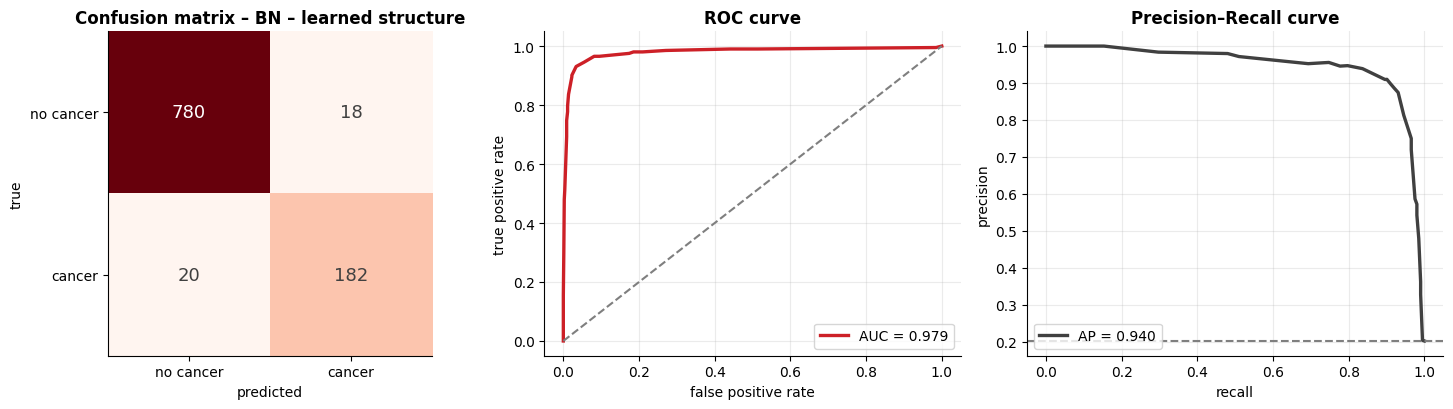

,accuracy,recall,precision,F1,ROC AUC,PR AUC,test log-likelihood / sample,BIC (train)
true structure,0.962,0.901,0.910,0.905,0.979,0.94,-2.582,-12736.164
learned structure,0.962,0.901,0.910,0.905,0.979,0.94,-2.582,-12736.164
Naive Bayes structure,0.932,0.807,0.849,0.827,0.973,0.91,-2.905,-14098.967


In [27]:
#Classify "Cancer" with the Bayesian Networks ( True, Learned and Naive Bayes Structures ) – Generic Metrics
target = IDX["Cancer"]
nb_parents = {v: ((target,) if v != target else ()) for v in range(len(NAMES))}
nets = {"true structure": bn_true, "learned structure": DiscreteBN(learned_parents, cards).fit(D_train), "Naive Bayes structure": DiscreteBN(nb_parents, cards).fit(D_train)}
y_c = D_test[:, target]
res_bn = {}
for name, net in nets.items():
    p = net.posterior_binary(D_test, target)
    res_bn[name] = report_binary(y_c, (p >= 0.5).astype(int), p, f"BN – {name}", ["no cancer", "cancer"], plot=(name == "learned structure"))
pd.DataFrame(res_bn).T[["accuracy", "recall", "precision", "F1", "ROC AUC", "PR AUC"]].assign(
    **{"test log-likelihood / sample": [net.loglik(D_test) / len(D_test) for net in nets.values()], "BIC (train)": [net.bic(D_train) for net in nets.values()]}).round(3)

Observe that the **true** and the **learned** structures give **identical** results, and that Naive Bayes (which wrongly assumes the symptoms are independent given cancer) has a **worse likelihood and BIC**.

#### **Bayesian Network on Real Data: Breast Cancer**

Attributes discretised into 3 quantile bins; the class is a node. We compare **Naive Bayes** (star structure) with a structure **learned from the data**.

In [28]:
#Prepare the Real Data ( 8 Discretised Attributes + Class ) and Check the Naive Bayes Network Against scikit-learn
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.naive_bayes import CategoricalNB

feat8 = ["mean radius", "mean texture", "mean smoothness", "mean compactness", "mean concavity", "mean concave points", "mean symmetry", "mean fractal dimension"]
kb = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(Xb_tr[feat8])
Dr_tr = np.c_[kb.transform(Xb_tr[feat8]).astype(int), yb_tr.to_numpy()]
Dr_te = np.c_[kb.transform(Xb_te[feat8]).astype(int), yb_te.to_numpy()]
names_r = [f.replace("mean ", "") for f in feat8] + ["MALIGNANT"]
cards_r = [3] * 8 + [2]
cls = 8

nb_net = DiscreteBN({v: ((cls,) if v != cls else ()) for v in range(9)}, cards_r).fit(Dr_tr)
nb_net.cpt_[cls] = np.array([[1 - Dr_tr[:, cls].mean(), Dr_tr[:, cls].mean()]])                 # scikit-learn does not smooth the class prior
p_nb = nb_net.posterior_binary(Dr_te, cls)
sk_nb = CategoricalNB(alpha=1.0, min_categories=3).fit(Dr_tr[:, :8], Dr_tr[:, 8])
print("our Naive Bayes network == scikit-learn CategoricalNB (max |Δ probability|):", f"{np.abs(p_nb - sk_nb.predict_proba(Dr_te[:, :8])[:, 1]).max():.2e}")

our Naive Bayes network == scikit-learn CategoricalNB (max |Δ probability|): 7.77e-16


edges learned: 11 | BIC (train): -2937.3 vs Naive Bayes: -3299.4


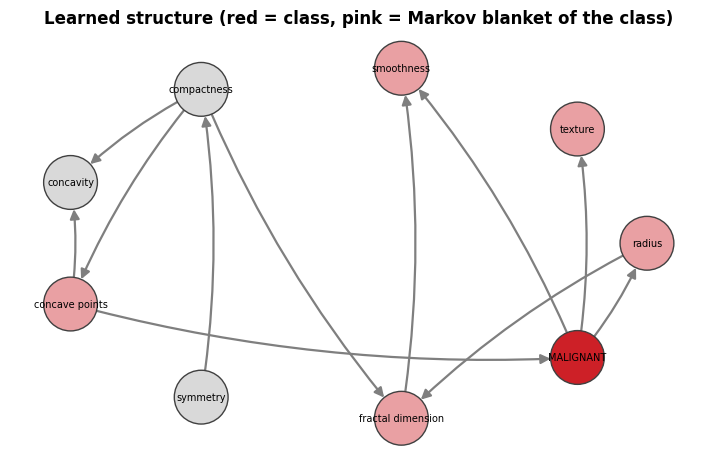

Markov blanket of the class: ['concave points', 'fractal dimension', 'radius', 'smoothness', 'texture']


In [29]:
#Learn the Structure from the Data ( Hill-Climbing + Restarts, at Most 3 Parents ) and Draw the Network
parents_r, hist_r, _ = hill_climb_restarts(Dr_tr, cards_r, n_restarts=15, max_parents=3)
bn_r = DiscreteBN(parents_r, cards_r).fit(Dr_tr)
edges_r = [(names_r[u], names_r[v]) for v, pa in parents_r.items() for u in pa]
print("edges learned:", len(edges_r), "| BIC (train):", round(bn_r.bic(Dr_tr), 1), "vs Naive Bayes:", round(nb_net.bic(Dr_tr), 1))

G = nx.DiGraph(); G.add_nodes_from(names_r); G.add_edges_from(edges_r)
mb = set(parents_r[cls]) | {v for v in range(9) if cls in parents_r[v]} | {p for v in range(9) if cls in parents_r[v] for p in parents_r[v] if p != cls}
fig, ax = plt.subplots(figsize=(9, 5.5))
pos_r = nx.circular_layout(G)
nx.draw_networkx(G, pos_r, ax=ax, node_color=[RED if n == "MALIGNANT" else (SOFT if names_r.index(n) in mb else LIGHT) for n in G.nodes], edgecolors=DARK, node_size=1500, font_size=7, edge_color=GRAY, width=1.6, arrowsize=14, connectionstyle="arc3,rad=0.08")
ax.set_title("Learned structure (red = class, pink = Markov blanket of the class)"); ax.axis("off"); plt.show()
print("Markov blanket of the class:", sorted(names_r[i] for i in mb))

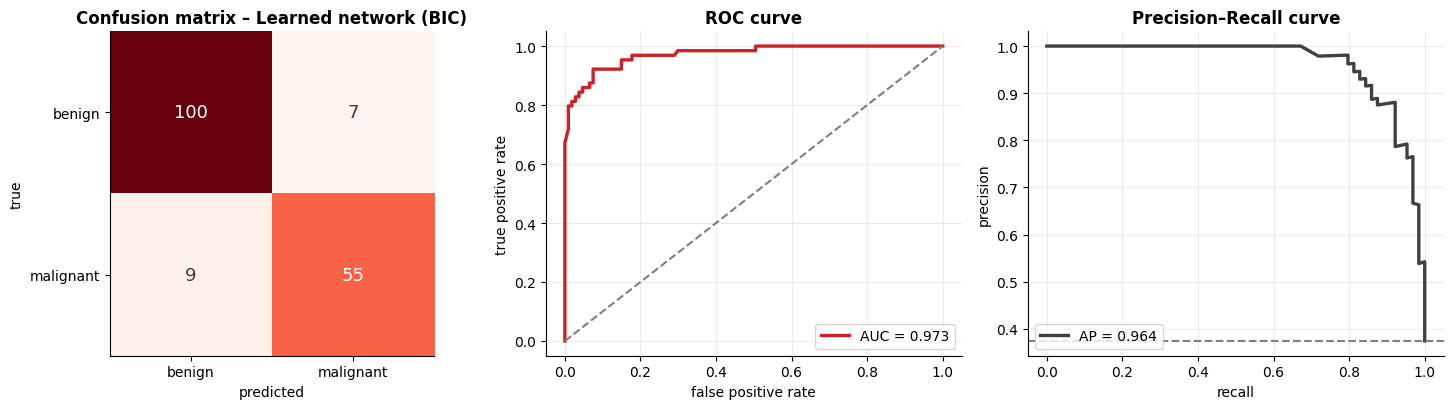

,accuracy,recall,precision,F1,ROC AUC,PR AUC,test log-loss,parameters
Naive Bayes network,0.912,0.891,0.877,0.884,0.970,0.956,0.323,33
Learned network (BIC),0.906,0.859,0.887,0.873,0.973,0.964,0.215,73
Logistic regression (same 8),0.942,0.922,0.922,0.922,0.989,0.983,0.139,9


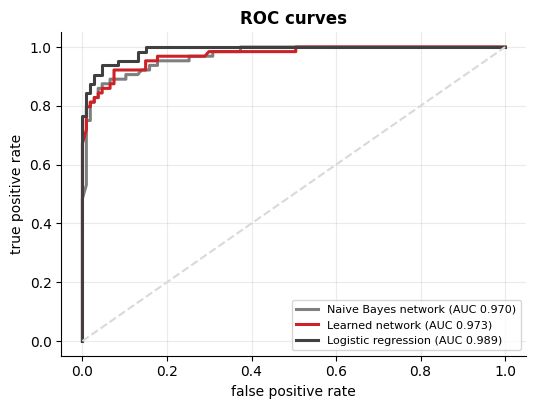

In [30]:
#Evaluate the Network Classifiers on the Real Test Set and Compare with Logistic Regression
p_bn = bn_r.posterior_binary(Dr_te, cls)
res_real = {}
res_real["Naive Bayes network"] = report_binary(yb_te, (p_nb >= 0.5).astype(int), p_nb, "Naive Bayes network", CLASSES, plot=False)
res_real["Learned network (BIC)"] = report_binary(yb_te, (p_bn >= 0.5).astype(int), p_bn, "Learned network (BIC)", CLASSES)
lr8 = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=20000)).fit(Xb_tr[feat8], yb_tr)
p_lr8 = lr8.predict_proba(Xb_te[feat8])[:, 1]
res_real["Logistic regression (same 8)"] = report_binary(yb_te, (p_lr8 >= 0.5).astype(int), p_lr8, "Logistic regression (same 8 attributes)", CLASSES, plot=False)

table = pd.DataFrame(res_real).T[["accuracy", "recall", "precision", "F1", "ROC AUC", "PR AUC"]]
table["test log-loss"] = [log_loss(yb_te, p) for p in (p_nb, p_bn, p_lr8)]
table["parameters"] = [sum(c.size - len(c) for c in nb_net.cpt_.values()), sum(c.size - len(c) for c in bn_r.cpt_.values()), 9]
display(table.round(3))

fig, ax = plt.subplots(figsize=(6, 4.2))
for (name, p), color in zip({"Naive Bayes network": p_nb, "Learned network": p_bn, "Logistic regression": p_lr8}.items(), [GRAY, RED, DARK]):
    f, t, _ = roc_curve(yb_te, p); ax.plot(f, t, color=color, lw=2.2, label=f"{name} (AUC {roc_auc_score(yb_te, p):.3f})")
ax.plot([0, 1], [0, 1], color=LIGHT, ls="--"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_title("ROC curves"); ax.legend(loc="lower right", fontsize=8)
plt.show()

The learned network gives **better probabilities** than Naive Bayes (test log-loss ≈ 0.22 vs 0.32) but **not** better accuracy; the **logistic regression**, which keeps the continuous attributes, is the best here – **discretisation loses information**.

### **5. Summary**

| | **Linear regression** | **Logistic regression** | **Bayesian network** |
|---|---|---|---|
| Estimation | least squares | maximum likelihood (IRLS) | counting + structure search (BIC) |
| Specific metrics | R², adjusted R², F, AIC/BIC, RMSE/MAE, VIF, Cook's D, interval coverage | log-loss, Brier, calibration, KS/Gini, Hosmer–Lemeshow, odds ratios | log-likelihood, BIC, KL divergence, SHD / structure F1 |
| Diagnostics | residual plots, Q-Q, tests | calibration, threshold analysis | v-structures, explaining away, Markov blanket |
| Main risk | collinearity, non-linearity | separation, overfitting with many attributes | structure uncertainty, discretisation |
| Python | `statsmodels`, `sklearn.linear_model` | `statsmodels`, `LogisticRegression` | `pgmpy`, `bnlearn` |